In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from plots import *
from helper import *
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from category_encoders import CountEncoder
from sklearn.model_selection import TimeSeriesSplit, cross_validate, train_test_split
from sklearn.base import clone
from xgboost import XGBRegressor
import optuna
from funcs import datetime_processing_func, noise_processing_func, lag_feature_func, region_generation_func

In [2]:
df_prices = pd.read_csv("C:/Users/redli/OneDrive/Desktop/classic ml tasks/regression/Hourly_Gasoline_Prices.csv")
df_fuel_st_info = pd.read_csv(r"C:\Users\redli\OneDrive\Desktop\classic ml tasks\regression\Fuel_Station_Information.csv")

In [3]:
df_full_eda = pd.merge(df_prices, df_fuel_st_info, how = "inner", on = "Id")
df_full_eda.head(30)

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
5,12494,1,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
6,37593,0,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
7,37593,1,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
8,50047,0,1.879,2022-01-02 14:20:37,DI BENEDETTO MARIA AGATA,SP Energia Siciliana,Stradale,stzione di servizio Di Benedetto Maria Agata,VENTIMIGLIA DI SICILIA,37.920051,13.565093
9,52185,0,1.800,2022-01-02 17:25:08,PIRA GIANPAOLO,Q8,Stradale,PIRA GIANPAOLO,BITTI,40.476894,9.382334


In [4]:
from funcs import datetime_processing_func,noise_processing_func

In [5]:
dt_proc = FunctionTransformer(datetime_processing_func)
noise_proc = FunctionTransformer(noise_processing_func)

In [6]:
df_full_eda.head()

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766


In [7]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator
from sklearn.impute import SimpleImputer
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error
import joblib
from funcs import datetime_processing_func, noise_processing_func, train_test_splitting

bundle = joblib.load("xgboost_model.joblib")

In [8]:
pipe = bundle["pipeline"]
hptunned_model = bundle["xgboost"]
hptunned_metrics = bundle["metrics"]

In [9]:
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dt_proc', ...), ('noise_proc', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['isSelf','Date','Fuel_station_manager',...,'City','Latitude', 'Longitudine']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function dat...001FF206B41A0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False


In [10]:
def metrics_calculate(pipe, X_train, X_test, y_train, y_test):
    temp_pipe = clone(pipe)

    X_train_proc = temp_pipe.fit_transform(X_train, y_train)
    X_test_proc = temp_pipe.transform(X_test)

    temp_model = clone(hptunned_model)

    temp_model.fit(X_train_proc, y_train)
    y_pred = temp_model.predict(X_test_proc)

    temp_result_metrics = {"R2" : r2_score(y_test, y_pred), 
                       "MAE" : mean_absolute_percentage_error(y_test, y_pred), 
                       "RMSE" :(target_mean - root_mean_squared_error(y_test, y_pred))/target_mean}
    
    diff_metrics = {k: temp_result_metrics[k] - hptunned_metrics[k] for k in temp_result_metrics}
    sns.heatmap(pd.Series(diff_metrics).to_frame(), annot= True, cmap = 'coolwarm')

    return temp_result_metrics

# Feature engineering

Первое что приходит в голову, конечно как то сохранять историю цен и передавать ее в признак (Идея моя, но то как примерно реализовать спрашивал у клода). В первую очередь попытаюсь доавбить лаг признак, вытащу таргет, смещу на одну позицию в перед, так что для каждого ценника будет сущетсвовать ценник, записанный в предыдущий раз, этой же компании

In [11]:
df_full_eda = df_full_eda.sort_values("Date")

df_w_price_lag = df_full_eda.copy()

df_w_price_lag["price_lag"] = df_full_eda.groupby(["Petrol_company"])["Price"].shift(1)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.012016 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2239
[LightGBM] [Info] Number of data points in the train set: 1943945, number of used features: 11
[LightGBM] [Info] Start training from score 1.864135


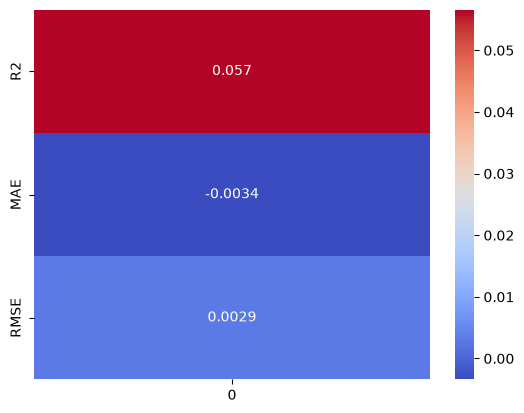

In [12]:
target_mean = df_full_eda["Price"].mean()

X_train, X_test, y_train,  y_test = train_test_splitting(df_w_price_lag)

result_metrics_1 = metrics_calculate(pipe, X_train, X_test, y_train,  y_test)

Как видно из графика на пол сотой доли вырос R2, что определенно плюс, значит у модели появился признак, который лучше описывает тенденция в данных

Так же одно из немногих потенциальных способов увелечения итогового скора это создание признака "Область"(Тоже самое, что и с предыдущим, решение мое, изначально хотел делать с dbscan, но потом решил, что будет черезчур, так что решил заменить на обычный kmeans), в датасете присутствуют значения Ширины и Долготы, при помощи dbscan или kmean, как в моем случае, можно будет выделить класстеры, для которых модель может выделить завимость

In [13]:
target_mean = df_full_eda["Price"].mean()
result_metrics = {}

fill_na_coords = SimpleImputer(strategy = "mean").fit_transform(df_full_eda[["Latitude", "Longitudine"]])

region_generation_model = KMeans(n_clusters = 10)

regions = region_generation_model.fit_predict(fill_na_coords)

df_w_coords = df_full_eda.copy()
df_w_coords["Regions"] = regions

In [14]:
df_w_coords

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine,Regions
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216,1
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323,6
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323,6
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976,0
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766,5
...,...,...,...,...,...,...,...,...,...,...,...,...
2451424,48073,0,1.869,2022-12-31 07:59:50,CALOR SYSTEMS S.R.L.,Api-Ip,Stradale,PIOLTELLO MANTEGNA,PIOLTELLO,45.503685,9.330787,9
2451425,48073,1,1.639,2022-12-31 07:59:50,CALOR SYSTEMS S.R.L.,Api-Ip,Stradale,PIOLTELLO MANTEGNA,PIOLTELLO,45.503685,9.330787,9
2451426,27829,0,1.659,2022-12-31 07:59:55,IP G.L. Carburanti e gomme,Api-Ip,Stradale,IP G.L. Carburanti e gomme,LANCIANO,42.225105,14.405091,0
2451427,14415,1,1.619,2022-12-31 07:59:57,SELF AREA AGIP DI FRANCOLINI FABIO & MORETTI G...,Agip Eni,Stradale,SELF AREA AGIP DI FRANCOLINI FABIO & MORETTI G...,PESARO,43.896590,12.904783,4


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009995 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1992
[LightGBM] [Info] Number of data points in the train set: 1915684, number of used features: 11
[LightGBM] [Info] Start training from score 1.865682


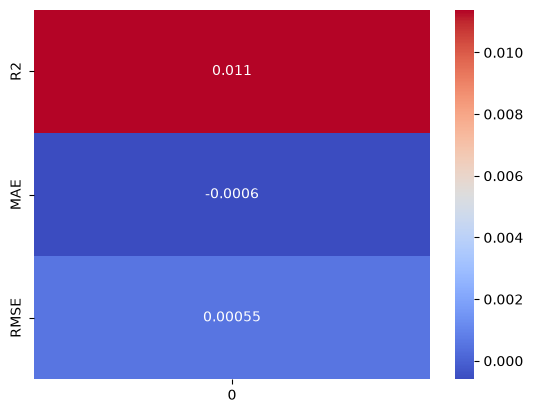

In [15]:
X_train, X_test, y_train, y_test = train_test_splitting(df_w_coords)

result_metrics_2 = metrics_calculate(pipe, X_train, X_test, y_train, y_test)

Незначительно вырос показатель R2, а так же RMSE

In [16]:
if "manager_ecoder" == pipe["transformer"].transformers[2][0]:
    pipe["transformer"].transformers[2] = ("manager_encoder", pipe["transformer"].transformers[2][1], pipe["transformer"].transformers[2][2])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016133 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1229
[LightGBM] [Info] Number of data points in the train set: 1915684, number of used features: 7
[LightGBM] [Info] Start training from score 1.865682


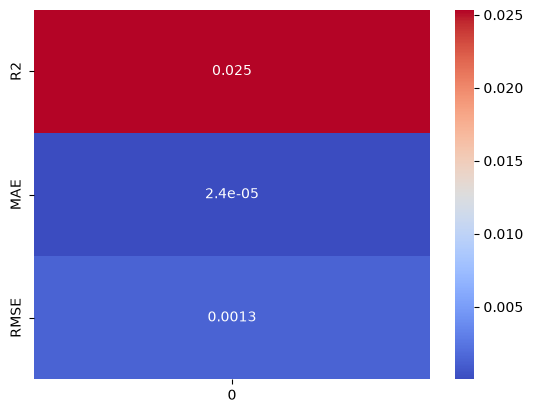

In [17]:
alt_pipe = clone(pipe)
alt_pipe.set_params(
        transformer__city_encoder='drop',
        transformer__manager_encoder='drop',
        transformer__company_encoder='drop'
    )
X_train, X_test, y_train, y_test = train_test_splitting(df_full_eda)

result_metrics_3 = metrics_calculate(alt_pipe, X_train, X_test, y_train, y_test)

Значения упали, что ожидаемо, идея если честно так себе, в итоге получилось падение по всем метрикам

In [18]:
df_full_eda.head()

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766


In [19]:
lag_feature_transformer = FunctionTransformer(lag_feature_func, kw_args={"sort_feature" : ["Date"]})
region_generation = FunctionTransformer(region_generation_func)

In [22]:
final_pipe = list(clone(pipe).steps)
final_pipe.insert(2, ("price_lag", lag_feature_transformer))
final_pipe.insert(3, ("regions", region_generation))
final_pipe.insert(5, ("dropper", ColumnTransformer([("drop_cols", "drop", ["Id"])], remainder='passthrough')))
final_pipe = Pipeline(final_pipe[:-2])
final_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dt_proc', ...), ('noise_proc', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function dat...001FF206B41A0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictio

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014548 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1986
[LightGBM] [Info] Number of data points in the train set: 1915332, number of used features: 11
[LightGBM] [Info] Start training from score 1.865698


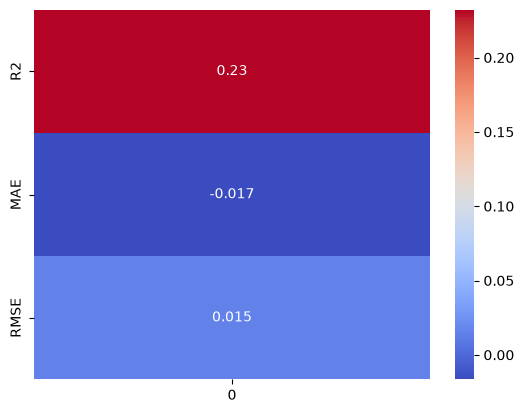

In [23]:
temp_pipe = clone(final_pipe)
df_curr = temp_pipe[:4].fit_transform(df_full_eda.drop_duplicates())

X_train, X_test, y_train, y_test = train_test_splitting(df_curr)
result_metrics = metrics_calculate(temp_pipe[4:], X_train, X_test, y_train, y_test)

In [24]:
result_metrics

{'R2': 0.787842947491801,
 'MAE': 0.022666573270921992,
 'RMSE': np.float64(0.9660896445666296)}

In [25]:
results = {
    "pipeline" : final_pipe,
    "model" : hptunned_model,
    "metrics" : result_metrics
}

In [26]:
joblib.dump(results, "final_result.joblib")

['final_result.joblib']